# EDR/XDR Sistemlerinde Davranışsal Anomali Tespiti — Küçük Ölçekli Simülasyon

**Öğrenci:** Sümeyye İkiz

**Staj Konusu:** EDR/XDR sistemlerinde kullanılan davranışsal anomali tespiti yaklaşımlarının küçük ölçekli bir simülasyonunun geliştirilmesi

## Proje Özeti

Bu proje, EDR/XDR (Endpoint/Extended Detection & Response) sistemlerinin kullandığı davranışsal, unsupervised (etiketsiz) anomali tespiti yaklaşımını küçük ölçekte simüle etmeyi amaçlamaktadır. Model, yalnızca normal (Benign) network trafiği ile eğitilmiş; saldırı trafiği ise modelin hiç görmediği bir "anomali" olarak test aşamasında değerlendirilmiştir.

## Veri Seti

CICIDS2018 veri setinin 10 günlük trafik kaydından yalnızca **Wednesday-14-02-2018** gününe ait CSV dosyası kullanılmıştır. Bu dosya, veri setinin diğer günlerinde yer alan DDoS, Bot, SQL Injection gibi saldırı türlerini içermemekte; yalnızca **FTP-BruteForce** ve **SSH-Bruteforce** saldırılarını barındırmaktadır. Bu saldırı türü bilinçli olarak seçilmiştir: güncel tehdit istihbaratı raporlarına göre brute force saldırıları hâlâ en yaygın ilk-erişim (initial access) tekniklerinden biridir (2025 Verizon DBIR raporuna göre temel web uygulamalarına yönelik brute force saldırıları bir yıl içinde yaklaşık %20'den %60'a çıkmıştır).

## Yöntem Özeti

Yöntem, geliştirme sürecinde birkaç kez revize edilmiştir; bu revizyonların gerekçeleri ilgili hücrelerin öncesinde ayrı ayrı açıklanmıştır. Özetle:

1. Tek tek network flow'una bakmak yerine, olay-zinciri mantığıyla ardışık flow dizileri (sequence) oluşturulmuştur.
2. Model, yalnızca normal trafikle eğitilen bir **LSTM Autoencoder** olarak tasarlanmıştır.
3. Veri kalitesi sorunları (istatistiksel aşırı değerler) tespit edilip sistematik olarak temizlenmiştir.
4. Model mimarisi ve eğitim süreci (aktivasyon fonksiyonu, EarlyStopping) kademeli olarak iyileştirilmiştir.
5. Nihai eşik seçimi, güvenlik önceliği (saldırı kaçırmama) gözetilerek yapılmıştır.

**Not:** Bu notebook, geliştirme sürecinde yazarın kendi Google Drive hesabına bağlanarak çalıştırılmıştır. Kodun yeniden çalıştırılması isteniyorsa, veri setinin kullanıcının kendi Drive'ına indirilmesi ve `drive_path` değişkeninin buna göre güncellenmesi gerekmektedir.

**Not: Model İsimlendirmesi Hakkında**

Geliştirme sürecinde modeller kronolojik sırayla oluşturulmuş, ancak değişken isimleri tam sıralı bir numaralandırma (v1, v2, v3...) izlememiştir; bazı isimler yapılan değişikliği (örneğin window boyutu veya veri temizliği) vurgulamak amacıyla tanımlayıcı şekilde verilmiştir. Modellerin gerçek kronolojik sırası şu şekildedir:

| Sıra | Değişken Adı | Açıklama |
|---|---|---|
| 1 | `lstm_autoencoder` / `history` | İlk model (relu, kirli veri, 10 epoch) |
| 2 | `lstm_autoencoder_v2` / `history_v2` | Epoch sayısı artırıldı (25 epoch) |
| 3 | `lstm_autoencoder_v3` / `history_v3` | Aktivasyon fonksiyonu değiştirildi (tanh) |
| 4 | `lstm_autoencoder_w20` / `history_w20` | Window boyutu denemesi (window=20) |
| 5 | `lstm_autoencoder_clean` / `history_clean` | Outlier temizliği sonrası (window=10, tanh) |
| 6 | `lstm_autoencoder_v5_earlystop_p5` / `history_v5_earlystop_p5` | EarlyStopping denemesi (patience=5) |
| 7 | `lstm_autoencoder_v6` / `history_v6` | **Nihai model** (EarlyStopping, patience=8) |

In [8]:
from google.colab import drive
drive.mount('/content/drive')

import os
drive_path = '/content/drive/MyDrive/cicids2018_data'

if not os.path.exists(drive_path):
    os.environ['KAGGLE_API_TOKEN'] = "KENDI_KAGGLE_TOKENINIZI_BURAYA_GIRIN"
    !pip install kaggle --upgrade -q
    !kaggle datasets download -d towhidultonmoy/cicids2018
    !unzip -q cicids2018.zip -d /content/drive/MyDrive/cicids2018_data
    print("Veri indirildi ve Drive'a kaydedildi.")
else:
    print("Veri zaten Drive'da mevcut.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Veri zaten Drive'da mevcut.


## 1. Veri Yükleme ve Temel Temizlik

Kaggle API üzerinden indirilen CICIDS2018 veri setinin Wednesday-14-02-2018 günü CSV dosyası okunmuştur. Bu aşamada:

- Sonsuz (`inf`) ve eksik (`NaN`) değerler temizlenmiştir (CICIDS veri setlerinde `Flow Byts/s` gibi bölme işlemlerinden kaynaklanan bilinen bir sorun).
- Timestamp sütununda bir kısım kaydın hatalı (1970 yılına ait, teknik olarak geçersiz) olduğu tespit edilip bu satırlar veri setinden çıkarılmıştır.
- Veri, olay-zinciri (sequence) oluşturma adımına hazırlık olarak hedef port (Dst Port) ve zaman damgasına göre sıralanmıştır.
- Sinir ağı eğitimlerinin farklı çalıştırmalar arasında tutarlı ve tekrarlanabilir sonuçlar üretmesi amacıyla rastgelelik tohumu (`SEED=42`) sabitlenmiştir; bu, akademik ve endüstriyel makine öğrenmesi uygulamalarında standart bir pratiktir.

Bu adımlar sonucunda 1.048.575 satırdan 1.044.746 satıra düşülmüş (yaklaşık %0.4 veri kaybı), sınıf dağılımının (Benign / FTP-BruteForce / SSH-Bruteforce) korunduğu doğrulanmıştır.

In [9]:
import pandas as pd
import numpy as np
import tensorflow as tf
import random

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

df = pd.read_csv('/content/drive/MyDrive/cicids2018_data/Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv')
df_clean = df.replace([np.inf, -np.inf], np.nan).dropna()

df_seq = df_clean.copy()
df_seq['Timestamp_dt'] = pd.to_datetime(df_seq['Timestamp'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df_seq = df_seq[df_seq['Timestamp_dt'].dt.year == 2018].reset_index(drop=True)
df_seq = df_seq.sort_values(['Dst Port', 'Timestamp_dt']).reset_index(drop=True)

print("Temiz satır sayısı:", df_seq.shape[0])
print(df_seq['Label'].value_counts())

Temiz satır sayısı: 1044746
Label
Benign            663803
FTP-BruteForce    193354
SSH-Bruteforce    187589
Name: count, dtype: int64


## 2. Sınıf Dağılımının Görselleştirilmesi

Yukarıda elde edilen sınıf dağılımı, oranların daha kolay kavranabilmesi için bir bar grafiğiyle görselleştirilmiştir. Veri setinin yaklaşık %64'ünü normal (Benign) trafik, %36'sını ise saldırı trafiği (FTP-BruteForce ve SSH-Bruteforce) oluşturmaktadır. Bu oran, ileride kurulacak modelin hem yeterli normal veriyle eğitilebilmesi hem de test aşamasında anlamlı sayıda saldırı örneğiyle değerlendirilebilmesi açısından uygun bulunmuştur.

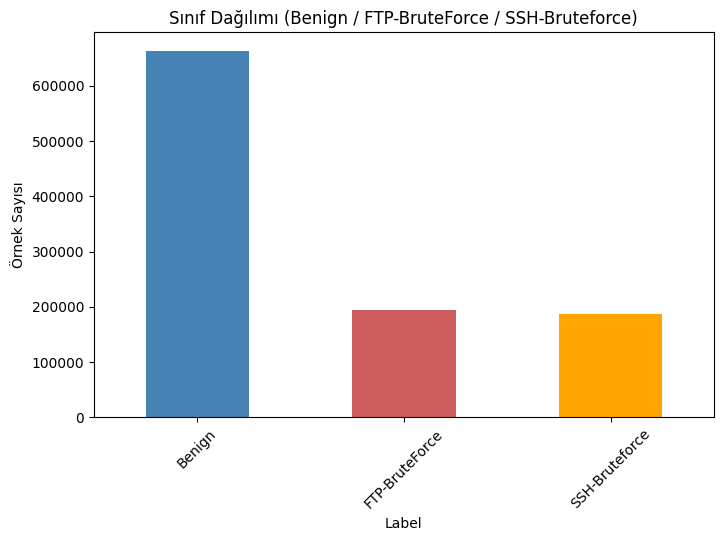

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df_seq['Label'].value_counts().plot(kind='bar', color=['steelblue','indianred','orange'])
plt.title('Sınıf Dağılımı (Benign / FTP-BruteForce / SSH-Bruteforce)')
plt.ylabel('Örnek Sayısı')
plt.xticks(rotation=45)
plt.show()

## 3. Olay Zinciri Yaklaşımı: Dizi (Sequence) Oluşturma

Gerçek EDR/XDR sistemlerinin tek bir olaya değil, olay zincirlerine/dizilerine bakarak korelasyon yaptığı bilinmektedir (bkz. CrowdStrike, Palo Alto Cortex XDR gibi platformların davranışsal analiz yaklaşımları). Bu doğrultuda, veri setindeki tek tek network flow'larına bağımsız bakmak yerine, aynı hedef porta (Dst Port) kısa zaman aralığında gelen **10 ardışık flow'dan** oluşan diziler oluşturulmuştur.

Bir dizi içinde en az bir saldırı satırı bulunması durumunda, tüm dizi "Attack" olarak etiketlenmiştir (muhafazakar bir etiketleme stratejisi); yalnızca tamamı normal olan diziler "Benign" sayılmıştır. Bu yaklaşım, özellikle veri setindeki FTP-BruteForce ve SSH-Bruteforce saldırılarının doğasına uygundur, çünkü brute force saldırıları zaten belirli bir portu kısa sürede tekrar tekrar hedefleyen bir davranış sergilemektedir.

Pencere boyutu (window_size=10), sistematik bir optimizasyon sonucu değil, saldırı örüntüsünün birkaç satırdan fazla veri gerektirdiği gözlemine dayanan makul bir başlangıç değeri olarak seçilmiştir; bu, ilerleyen bölümlerde (window_size=20 denemesi) sistematik olarak sınanmıştır.

Bu işlem sonucunda toplam **100.615 dizi** elde edilmiş; bunların 62.513'ü tamamen normal (Benign), 38.102'si en az bir saldırı içeren (Attack) dizilerdir.

In [11]:
window_size = 10
sequences = []
seq_labels = []

for port, group in df_seq.groupby('Dst Port'):
    group = group.reset_index(drop=True)
    n = len(group)
    for i in range(0, n - window_size + 1, window_size):
        block = group.iloc[i:i+window_size]
        sequences.append(block.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).values)
        seq_labels.append('Benign' if (block['Label'] == 'Benign').all() else 'Attack')

sequences = np.array(sequences)
seq_labels = np.array(seq_labels)

print("Toplam dizi sayısı:", sequences.shape)
print("Benign:", (seq_labels == 'Benign').sum(), "| Attack:", (seq_labels == 'Attack').sum())

Toplam dizi sayısı: (100615, 10, 77)
Benign: 62513 | Attack: 38102


## 4. Benign/Attack Ayrımı, Train/Test Bölünmesi ve Normalizasyon

Unsupervised (yalnızca normal davranışla eğitim) yaklaşımın uygulanabilmesi için, oluşturulan diziler önce **Benign** ve **Attack** olarak ikiye ayrılmıştır. Yalnızca Benign diziler eğitim/test olarak bölünmüş (%70 eğitim, %30 test); **Attack etiketli hiçbir dizi eğitim setine dahil edilmemiştir** — böylece model, saldırı örneklerini hiç görmeden yalnızca normal davranışı öğrenmektedir.

Normalizasyon (`StandardScaler`) veri sızıntısını (data leakage) önlemek amacıyla yalnızca eğitim (Benign train) verisiyle "öğrenilmiş", ardından bu öğrenilen ölçek hem test-normal hem de test-saldırı verisine uygulanmıştır. Diziler 3 boyutlu (örnek, zaman adımı, öznitelik) olduğu için, ölçekleme öncesinde geçici olarak 2 boyuta indirgenip işlem sonrası tekrar orijinal şekline dönüştürülmüştür.

Sonuç olarak model, **43.759 normal dizi** ile eğitilecek; **18.754 normal** ve **38.102 saldırı** dizisi ise yalnızca değerlendirme (test) aşamasında kullanılacaktır.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

seq_benign = sequences[seq_labels == 'Benign']
seq_attack = sequences[seq_labels == 'Attack']

seq_benign_train, seq_benign_test = train_test_split(seq_benign, test_size=0.3, random_state=42)

n_features = seq_benign_train.shape[2]
timesteps = seq_benign_train.shape[1]

scaler = StandardScaler()
scaler.fit(seq_benign_train.reshape(-1, n_features))

def scale_sequences(data):
    return scaler.transform(data.reshape(-1, n_features)).reshape(data.shape)

seq_benign_train_scaled = scale_sequences(seq_benign_train)
seq_benign_test_scaled = scale_sequences(seq_benign_test)
seq_attack_scaled = scale_sequences(seq_attack)

print("Eğitim:", seq_benign_train_scaled.shape, "| Test (normal):", seq_benign_test_scaled.shape, "| Test (saldırı):", seq_attack_scaled.shape)

Eğitim: (43759, 10, 77) | Test (normal): (18754, 10, 77) | Test (saldırı): (38102, 10, 77)


## 5. İlk Model Denemesi (V1): LSTM Autoencoder Mimarisi

Sıralı yapıya uygun olarak, Dense katmanlar yerine **LSTM tabanlı bir Autoencoder** mimarisi kurulmuştur. Model, girdiyi önce sıkıştırıp (encoder: 64→16 LSTM birimi) ardından geri açan (decoder: 16→64 LSTM birimi) bir yapıya sahiptir; çıkış katmanı (`TimeDistributed(Dense)`) her zaman adımı için ayrı ayrı öznitelik tahmini yapmaktadır.

Autoencoder'lar sınıflandırma değil yeniden inşa (reconstruction) görevi yaptığından, eğitim sırasında `accuracy` metriği hesaplanmamış; bunun yerine model başarısı **loss (MSE)** ile izlenmiştir. Model yalnızca normal (Benign) dizilerle, 10 epoch boyunca eğitilmiştir.

Bu ilk deneme, `relu` aktivasyon fonksiyonu ve henüz temizlenmemiş (outlier içeren) veriyle yapılmış olup, ilerleyen bölümlerde bu iki faktörün model performansına etkisi sistematik olarak incelenmiştir. Elde edilen sonuçta eğitim kaybı 0.58'den 0.44'e düşmüş; ancak doğrulama kaybındaki (val_loss) dalgalı seyir, bu ilk modelin henüz kararlı bir öğrenme sergilemediğine işaret etmektedir.

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

lstm_autoencoder = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='relu', return_sequences=True),
    layers.LSTM(16, activation='relu', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='relu', return_sequences=True),
    layers.LSTM(64, activation='relu', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder.compile(optimizer='adam', loss='mse')

history = lstm_autoencoder.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=10,
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled)
)

Epoch 1/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 22s 20ms/step - loss: 0.5793 - val_loss: 0.5725
Epoch 2/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.5106 - val_loss: 0.5562
Epoch 3/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.5000 - val_loss: 0.5274
Epoch 4/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4750 - val_loss: 0.5167
Epoch 5/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4651 - val_loss: 0.5031
Epoch 6/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.4548 - val_loss: 0.4947
Epoch 7/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.4518 - val_loss: 0.4922
Epoch 8/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4378 - val_loss: 0.4827
Epoch 9/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.4276 - val_loss: 0.4806
Epoch 10/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.4416 - val_loss: 0.5384


## 6. V1 Modelinin Eğitim Grafiği

Yukarıdaki eğitim sürecinin görsel karşılığı aşağıda sunulmuştur. Grafikte, doğrulama kaybının (turuncu çizgi) epoch'lar boyunca düzensiz bir seyir izlediği (iniş-çıkışlar gösterdiği) görülmektedir. Bu dalgalanma, ilerleyen bölümlerde tespit edilecek olan veri kalitesi sorunlarının (istatistiksel aşırı değerler) ve aktivasyon fonksiyonu seçiminin bir sonucu olarak değerlendirilmiş; bu iki faktör sistematik olarak ele alınmıştır.

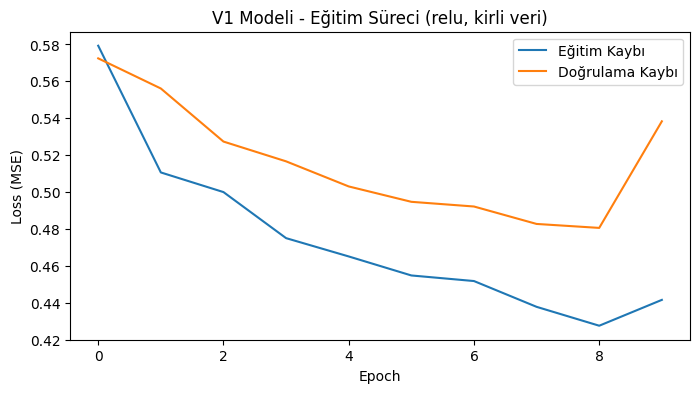

In [15]:
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.title('V1 Modeli - Eğitim Süreci (relu, kirli veri)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

## 7. Anomali Tespiti Mantığı: Reconstruction Error ve İlk Değerlendirme

Modelin "anomali tespit etme" mantığı şu prensibe dayanmaktadır: model yalnızca normal davranışla eğitildiği için, normal veriyi düşük hatayla (reconstruction error) yeniden üretebilirken, hiç görmediği saldırı verisini yeniden üretmekte zorlanacak ve daha yüksek hata verecektir. Bu hata (MSE), her dizi için ayrı ayrı hesaplanmış ve bir eşik değerinin üzerinde kalan diziler "Attack" olarak sınıflandırılmıştır.

İlk denemede eşik, normal test verisinin hata dağılımının **95. persentiline** göre belirlenmiştir. Bu eşikle yapılan sınıflandırmada, model saldırıları **%95 kesinlikle (precision)** tespit edebilse de, saldırıların ancak **%51'ini (recall)** yakalayabilmiş, genel doğruluk (accuracy) **%65** olarak ölçülmüştür. Bu, saldırıların yaklaşık yarısının kaçırıldığı, iyileştirmeye açık bir başlangıç sonucudur.

In [16]:
from sklearn.metrics import classification_report

def reconstruction_error(model, data):
    reconstructed = model.predict(data, verbose=0)
    return np.mean(np.square(data - reconstructed), axis=(1, 2))

error_benign_test = reconstruction_error(lstm_autoencoder, seq_benign_test_scaled)
error_attack = reconstruction_error(lstm_autoencoder, seq_attack_scaled)

threshold = np.percentile(error_benign_test, 95)
all_errors = np.concatenate([error_benign_test, error_attack])
all_true_labels = np.array(['Benign'] * len(error_benign_test) + ['Attack'] * len(error_attack))
all_pred_labels = np.where(all_errors > threshold, 'Attack', 'Benign')

print("Eşik:", threshold)
print(classification_report(all_true_labels, all_pred_labels))

Eşik: 1.2890998049376763
              precision    recall  f1-score   support

      Attack       0.95      0.51      0.66     38102
      Benign       0.49      0.95      0.64     18754

    accuracy                           0.65     56856
   macro avg       0.72      0.73      0.65     56856
weighted avg       0.80      0.65      0.66     56856



## 8. İkinci Deneme (V2): Epoch Sayısının Artırılması

İlk modelin (V1) düşük recall değerinin, modelin yetersiz eğitilmiş olmasından kaynaklanabileceği düşünülerek, aynı mimari (relu aktivasyonlu LSTM Autoencoder) bu kez **25 epoch** ile yeniden eğitilmiştir. Eğitim kaybı 0.59'dan 0.38'e düşmüş; ancak doğrulama kaybındaki dalgalı seyir (epoch 7, 13, 15, 24 gibi noktalarda gözlenen sıçramalar) bu modelde de devam etmiştir. Bu, sorunun yalnızca epoch sayısıyla ilgili olmadığını, model mimarisinde veya veri kalitesinde başka bir kaynağın da rol oynayabileceğini düşündürmüştür.

In [17]:
lstm_autoencoder_v2 = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='relu', return_sequences=True),
    layers.LSTM(16, activation='relu', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='relu', return_sequences=True),
    layers.LSTM(64, activation='relu', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder_v2.compile(optimizer='adam', loss='mse')

history_v2 = lstm_autoencoder_v2.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=25,
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled)
)

Epoch 1/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 0.5853 - val_loss: 0.5917
Epoch 2/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.5282 - val_loss: 0.5766
Epoch 3/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.5055 - val_loss: 0.5521
Epoch 4/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4871 - val_loss: 0.5300
Epoch 5/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4725 - val_loss: 0.5149
Epoch 6/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.4597 - val_loss: 0.5001
Epoch 7/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.4651 - val_loss: 0.5220
Epoch 8/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.4529 - val_loss: 0.5091
Epoch 9/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4348 - val_loss: 0.4877
Epoch 10/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.4295 - val_loss: 0.4749
Epoch 11/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4287 - val_loss: 0.4676
Epoch 12/25
684/684 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/s

## 9. V2 Modelinin Değerlendirilmesi: Epoch Artışının Sonuçlara Etkisi

V2 modelinin normal ve saldırı verisi üzerindeki ortalama hataları hesaplanmıştır: normal veride 0.43, saldırı verisinde 2.69 — yaklaşık **6.2 kat fark**, V1'e (5.5 kat) kıyasla hafif bir iyileşme göstermektedir. Ancak aynı sabit persentil (95.) eşik stratejisiyle yapılan sınıflandırmada, sonuç **V1 ile birebir aynı** çıkmıştır (Accuracy: %65, Attack Recall: %51).

Bu bulgu önemli bir gözlemi ortaya koymaktadır: modelin normal/saldırı ayırt etme kapasitesi (ham hata farkı) hafifçe artmış olsa da, **sabit bir persentil eşiği kullanmak bu iyileşmeyi sınıflandırma performansına yansıtamamaktadır.** Bu, sorunun büyük ölçüde eşik seçim stratejisinden kaynaklandığını düşündürmüş ve bir sonraki adımda optimal eşik arayışına yönlendirmiştir.

In [18]:
error_benign_test_v2 = reconstruction_error(lstm_autoencoder_v2, seq_benign_test_scaled)
error_attack_v2 = reconstruction_error(lstm_autoencoder_v2, seq_attack_scaled)

print("V2 - Normal test verisi ortalama hata:", error_benign_test_v2.mean())
print("V2 - Saldırı verisi ortalama hata:", error_attack_v2.mean())

threshold_v2 = np.percentile(error_benign_test_v2, 95)
all_errors_v2 = np.concatenate([error_benign_test_v2, error_attack_v2])
all_true_labels_v2 = np.array(['Benign'] * len(error_benign_test_v2) + ['Attack'] * len(error_attack_v2))
all_pred_labels_v2 = np.where(all_errors_v2 > threshold_v2, 'Attack', 'Benign')

print("\nEşik (V2):", threshold_v2)
print(classification_report(all_true_labels_v2, all_pred_labels_v2))

V2 - Normal test verisi ortalama hata: 0.430025814277882
V2 - Saldırı verisi ortalama hata: 2.6880753113971103

Eşik (V2): 1.0889851401552721
              precision    recall  f1-score   support

      Attack       0.95      0.51      0.66     38102
      Benign       0.49      0.95      0.64     18754

    accuracy                           0.65     56856
   macro avg       0.72      0.73      0.65     56856
weighted avg       0.80      0.65      0.66     56856



## 10. Optimal Eşik Arayışı: F1-Skor Optimizasyonu

Sabit bir persentil yerine, precision-recall eğrisi üzerinden **F1-skorunu maksimize eden eşik** matematiksel olarak hesaplanmıştır. Bu yöntem, `precision_recall_curve` fonksiyonuyla hatanın alabileceği her olası eşik değeri için precision ve recall'u hesaplayıp, ikisini dengeleyen (F1'i en yükseğe çıkaran) noktayı bulmaktadır.

Bu yaklaşımla elde edilen sonuç, önceki (sabit persentil) stratejisinden çarpıcı derecede farklıdır: **Attack recall %100'e çıkmış**, genel doğruluk **%65'ten %89'a** yükselmiştir. Ancak bu iyileşmenin bir bedeli vardır — Benign recall %68'e düşmüş, yani normal trafiğin **%32'si yanlışlıkla saldırı olarak işaretlenmiştir.** Bu, modelin "her şeyi saldırı say" gibi aşırı agresif bir noktaya kaydığına işaret eden bir bulgudur ve precision-recall dengesinin (trade-off) dikkatle yönetilmesi gerektiğini göstermektedir.

In [19]:
from sklearn.metrics import precision_recall_curve, f1_score

# Precision-Recall eğrisinden optimal eşiği bul (V2 modeli için)
y_true_binary = (all_true_labels_v2 == 'Attack').astype(int)
precisions, recalls, thresholds = precision_recall_curve(y_true_binary, all_errors_v2)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Optimal eşik (F1 maksimize eden):", best_threshold)
print("Bu eşikteki F1 skoru:", f1_scores[best_idx])

all_pred_optimal = np.where(all_errors_v2 > best_threshold, 'Attack', 'Benign')
print(classification_report(all_true_labels_v2, all_pred_optimal))

Optimal eşik (F1 maksimize eden): 0.22145953200691967
Bu eşikteki F1 skoru: 0.9258518011803537
              precision    recall  f1-score   support

      Attack       0.87      1.00      0.93     38102
      Benign       0.99      0.68      0.81     18754

    accuracy                           0.89     56856
   macro avg       0.93      0.84      0.87     56856
weighted avg       0.91      0.89      0.89     56856



## 11. Yanlış Alarm Oranının Doğrulanması

Bir önceki adımda gözlenen %32'lik Benign recall düşüşünün gerçekten yanlış alarm oranıyla tutarlı olduğu doğrulanmıştır: normal test verisinin **%31.5'i**, optimal eşiğin üzerinde kalmaktadır. Bu, güvenlik sistemlerinde sıkça karşılaşılan **precision-recall trade-off**'unu somut olarak göstermektedir: düşük bir eşik değeri saldırı kaçırma riskini azaltırken, yanlış alarm (false positive) oranını belirgin şekilde artırmaktadır. Bu bulgu, yalnızca eşik ayarlamanın yeterli olmadığını, modelin kendisinin de (mimari, aktivasyon fonksiyonu, veri kalitesi) iyileştirilmesi gerektiğini düşündürmüştür.

In [20]:
percentage_above = (error_benign_test_v2 > best_threshold).mean() * 100
print(f"Normal test verisinin %{percentage_above:.1f}'i bu eşiğin üstünde")

Normal test verisinin %31.5'i bu eşiğin üstünde


## 12. Üçüncü Deneme (V3): Aktivasyon Fonksiyonu Değişikliği

Buraya kadarki denemelerde gözlenen dalgalı doğrulama kaybının, `relu` aktivasyon fonksiyonunun LSTM hücreleri için ideal olmayabileceği düşüncesiyle, model **`tanh`** aktivasyonuyla yeniden kurulmuştur. `tanh`, LSTM'in iç kapı (gate) mekanizmalarıyla daha uyumlu, literatürde LSTM için daha sık tercih edilen bir aktivasyon fonksiyonudur.

30 epoch boyunca eğitilen bu model, eğitim kaybını 0.59'dan 0.33'e düşürmüş ve önceki modellere kıyasla **belirgin şekilde daha düzgün, daha az dalgalı** bir doğrulama kaybı eğrisi sergilemiştir. Bu, aktivasyon fonksiyonu değişikliğinin eğitim istikrarına olumlu katkısını göstermektedir.

In [21]:
lstm_autoencoder_v3 = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.LSTM(16, activation='tanh', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='tanh', return_sequences=True),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder_v3.compile(optimizer='adam', loss='mse')

history_v3 = lstm_autoencoder_v3.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=30,
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled)
)

Epoch 1/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - loss: 0.5924 - val_loss: 0.5832
Epoch 2/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.5210 - val_loss: 0.5525
Epoch 3/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.4944 - val_loss: 0.5329
Epoch 4/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.4742 - val_loss: 0.5133
Epoch 5/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.4552 - val_loss: 0.4988
Epoch 6/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.4418 - val_loss: 0.4993
Epoch 7/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.4288 - val_loss: 0.4806
Epoch 8/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.4223 - val_loss: 0.4686
Epoch 9/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.4145 - val_loss: 0.4645
Epoch 10/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.4104 - val_loss: 0.4579
Epoch 11/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.3963 - val_loss: 0.4793
Epoch 12/30
684/684 ━━━━━━━━━━━━━━━━━━

## 13. V3 Modelinin Değerlendirilmesi: Aktivasyon Değişikliğinin Etkisi

V3 modelinin normal/saldırı hata farkı **7.16 kat** olarak ölçülmüştür (V1: 5.5 kat, V2: 6.2 kat) — bu, `tanh` aktivasyonuna geçişin modelin ayırt etme kapasitesini gerçekten artırdığını göstermektedir. Optimal eşikle yapılan sınıflandırmada genel doğruluk **%90**'a, Benign recall ise **%72**'ye yükselmiştir (V2'de %68 idi).

Bu sonuç, hem eşik optimizasyonunun hem de model mimarisi/aktivasyon iyileştirmesinin **birbirini tamamlayan, kümülatif bir etkiye** sahip olduğunu göstermektedir. Ancak yanlış alarm oranı (%28) hâlâ yüksek kalmış olup, bu durumun veri kalitesiyle ilgili olup olmadığının araştırılmasına karar verilmiştir.

In [22]:
error_benign_test_v3 = reconstruction_error(lstm_autoencoder_v3, seq_benign_test_scaled)
error_attack_v3 = reconstruction_error(lstm_autoencoder_v3, seq_attack_scaled)

print("V3 - Normal test verisi ortalama hata:", error_benign_test_v3.mean())
print("V3 - Saldırı verisi ortalama hata:", error_attack_v3.mean())
print("Fark oranı:", error_attack_v3.mean() / error_benign_test_v3.mean())

# Optimal eşiği bul (F1 maksimize eden)
y_true_binary_v3 = (all_true_labels_v2 == 'Attack').astype(int)  # etiketler aynı, sadece hatalar farklı
all_errors_v3 = np.concatenate([error_benign_test_v3, error_attack_v3])

precisions_v3, recalls_v3, thresholds_v3 = precision_recall_curve(y_true_binary_v3, all_errors_v3)
f1_scores_v3 = 2 * (precisions_v3 * recalls_v3) / (precisions_v3 + recalls_v3 + 1e-10)
best_idx_v3 = np.argmax(f1_scores_v3)
best_threshold_v3 = thresholds_v3[best_idx_v3]

print("\nOptimal eşik (V3):", best_threshold_v3)
print("Bu eşikteki F1 skoru:", f1_scores_v3[best_idx_v3])

all_pred_v3 = np.where(all_errors_v3 > best_threshold_v3, 'Attack', 'Benign')
print(classification_report(all_true_labels_v2, all_pred_v3))

V3 - Normal test verisi ortalama hata: 0.3827237280234583
V3 - Saldırı verisi ortalama hata: 2.7387410879187004
Fark oranı: 7.155921850110205

Optimal eşik (V3): 0.22930106091952962
Bu eşikteki F1 skoru: 0.9326059443885037
              precision    recall  f1-score   support

      Attack       0.88      1.00      0.93     38102
      Benign       0.99      0.72      0.83     18754

    accuracy                           0.90     56856
   macro avg       0.93      0.86      0.88     56856
weighted avg       0.91      0.90      0.90     56856



## 14. Dördüncü Deneme: Pencere Boyutunun Değiştirilmesi (Window Size = 20)

Buraya kadar sabit tutulan pencere boyutu (10), brute force saldırı örüntüsünü daha güçlü yakalayıp yakalayamayacağını sınamak amacıyla **20**'ye çıkarılmıştır. Aynı dizi oluşturma, ayırma ve normalizasyon adımları bu yeni pencere boyutuyla tekrarlanmıştır.

Bu işlem sonucunda toplam **49.550 dizi** elde edilmiş (pencere büyüdüğü için doğal olarak dizi sayısı azalmıştır); bunların 30.498'i Benign, 19.052'si Attack'tır. Eğitim seti 21.348 diziye düşmüştür.

In [23]:
window_size_20 = 20
sequences_20 = []
seq_labels_20 = []

for port, group in df_seq.groupby('Dst Port'):
    group = group.reset_index(drop=True)
    n = len(group)
    for i in range(0, n - window_size_20 + 1, window_size_20):
        block = group.iloc[i:i+window_size_20]
        sequences_20.append(block.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).values)
        seq_labels_20.append('Benign' if (block['Label'] == 'Benign').all() else 'Attack')

sequences_20 = np.array(sequences_20)
seq_labels_20 = np.array(seq_labels_20)

print("Toplam dizi sayısı (window=20):", sequences_20.shape)
print("Benign:", (seq_labels_20 == 'Benign').sum(), "| Attack:", (seq_labels_20 == 'Attack').sum())

# Train/test ayır ve normalize et
seq_benign_20 = sequences_20[seq_labels_20 == 'Benign']
seq_attack_20 = sequences_20[seq_labels_20 == 'Attack']

seq_benign_train_20, seq_benign_test_20 = train_test_split(seq_benign_20, test_size=0.3, random_state=42)

n_features_20 = seq_benign_train_20.shape[2]
timesteps_20 = seq_benign_train_20.shape[1]

scaler_20 = StandardScaler()
scaler_20.fit(seq_benign_train_20.reshape(-1, n_features_20))

def scale_sequences_20(data):
    return scaler_20.transform(data.reshape(-1, n_features_20)).reshape(data.shape)

seq_benign_train_20_scaled = scale_sequences_20(seq_benign_train_20)
seq_benign_test_20_scaled = scale_sequences_20(seq_benign_test_20)
seq_attack_20_scaled = scale_sequences_20(seq_attack_20)

print("Eğitim:", seq_benign_train_20_scaled.shape, "| Test (saldırı):", seq_attack_20_scaled.shape)

Toplam dizi sayısı (window=20): (49550, 20, 77)
Benign: 30498 | Attack: 19052
Eğitim: (21348, 20, 77) | Test (saldırı): (19052, 20, 77)


## 15. Beklenmedik Bulgu: Anormal Doğrulama Kaybı

Window=20 modeli eğitildiğinde çarpıcı bir anomali fark edilmiştir: eğitim kaybı normal aralıkta (0.62 → 0.46) seyrederken, **doğrulama kaybı (val_loss) 36 civarında sabitlenmiş** kalmıştır — bu, eğitim kaybından yaklaşık **80 kat** daha yüksektir. Bu boyutta bir uçurum, önceki hiçbir denemede gözlenmemiştir.

Bu beklenmedik sonuç, modelin hatalı olmasından değil, **test verisinde istatistiksel bir aşırı değer (outlier)** bulunmasından kaynaklanabileceği hipoteziyle araştırılmıştır; bu araştırma sürecinin adımları aşağıda detaylandırılmıştır.

In [24]:
lstm_autoencoder_w20 = models.Sequential([
    layers.Input(shape=(timesteps_20, n_features_20)),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.LSTM(16, activation='tanh', return_sequences=False),
    layers.RepeatVector(timesteps_20),
    layers.LSTM(16, activation='tanh', return_sequences=True),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features_20))
])

lstm_autoencoder_w20.compile(optimizer='adam', loss='mse')

history_w20 = lstm_autoencoder_w20.fit(
    seq_benign_train_20_scaled, seq_benign_train_20_scaled,
    epochs=30,
    batch_size=64,
    validation_data=(seq_benign_test_20_scaled, seq_benign_test_20_scaled)
)

Epoch 1/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 0.6237 - val_loss: 36.5653
Epoch 2/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.5607 - val_loss: 36.5458
Epoch 3/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.5451 - val_loss: 36.5307
Epoch 4/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.5331 - val_loss: 36.5199
Epoch 5/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.5247 - val_loss: 36.5140
Epoch 6/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.5175 - val_loss: 36.4941
Epoch 7/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.5114 - val_loss: 36.4989
Epoch 8/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.5042 - val_loss: 36.4836
Epoch 9/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.5020 - val_loss: 36.4827
Epoch 10/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.4955 - val_loss: 36.4720
Epoch 11/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.4931 - val_loss: 36.4626
Epoch 12/30
334/334 ━━━━━━━━━

## 16. Aşırı Uç Değer (Outlier) Teşhisi

Hipotezi doğrulamak amacıyla, ölçeklenmiş (scaled) veri kümelerinin istatistiksel özetleri incelenmiştir. Sonuç net bir kanıt ortaya koymuştur: Train ve Test(Attack) kümelerinde maksimum değerler makul aralıkta (189 ve 27) iken, **Test(Normal) kümesinde maksimum değer 8499**'a kadar çıkmaktadır — bu, diğer kümelerden **onlarca kat** büyük bir sapmadır.

Detaylı incelemede, bu aşırı değerin **tek bir örnekte (index 6079)** yoğunlaştığı görülmüştür; diğer "sorunlu" görünen örneklerin (index 4617, 3456, 338, 659) maksimum değerleri aslında makul aralıktadır (106-142). Bu, klasik bir **tekil aşırı uç değer (single outlier)** durumudur.

In [25]:
print("=== Veri Boyutları ===")
print("Train (window=20):", seq_benign_train_20_scaled.shape)
print("Test normal (window=20):", seq_benign_test_20_scaled.shape)
print("Test saldırı (window=20):", seq_attack_20_scaled.shape)

print("\n=== Scaled Veri İstatistikleri ===")
print("Train  -> min:", seq_benign_train_20_scaled.min(), "max:", seq_benign_train_20_scaled.max())
print("Test(N)-> min:", seq_benign_test_20_scaled.min(), "max:", seq_benign_test_20_scaled.max())
print("Test(A)-> min:", seq_attack_20_scaled.min(), "max:", seq_attack_20_scaled.max())

print("\n=== Test (Normal) İçindeki En Uç 10 Değer ===")
flat_test = seq_benign_test_20_scaled.flatten()
print(np.sort(np.abs(flat_test))[-10:])

print("\n=== Hangi örnek(ler) bu uç değerleri içeriyor? ===")
per_sample_max = np.abs(seq_benign_test_20_scaled).max(axis=(1,2))
worst_samples = np.argsort(per_sample_max)[-5:]
print("En sorunlu 5 örneğin index'i:", worst_samples)
print("Bu örneklerin max mutlak değerleri:", per_sample_max[worst_samples])

=== Veri Boyutları ===
Train (window=20): (21348, 20, 77)
Test normal (window=20): (9150, 20, 77)
Test saldırı (window=20): (19052, 20, 77)

=== Scaled Veri İstatistikleri ===
Train  -> min: -2.5340886384210908 max: 189.77449072035733
Test(N)-> min: -2.5340886384210908 max: 8499.62259439634
Test(A)-> min: -0.9868123275997754 max: 26.581638570113732

=== Test (Normal) İçindeki En Uç 10 Değer ===
[ 385.19222795  861.08878805 6158.72154317 6158.72154317 8424.30353754
 8424.30353754 8476.95465494 8476.95465494 8499.6225944  8499.6225944 ]

=== Hangi örnek(ler) bu uç değerleri içeriyor? ===
En sorunlu 5 örneğin index'i: [4617 3456  338  659 6079]
Bu örneklerin max mutlak değerleri: [ 106.79830491  110.75524485  142.23298013  142.57151847 8499.6225944 ]


## 17. Hipotezin Doğrulanması: Tekil Outlier'ın Etkisi

Şüphelenilen tekil aşırı değer (index 6079), test kümesinden çıkarılıp model **yeniden eğitilmeden**, sadece bu temizlenmiş veriyle değerlendirilmiştir. Sonuç teşhisi kesin olarak doğrulamıştır: val_loss, **36'dan 0.43'e** (yaklaşık 84 kat) düşmüştür.

Bu, tek bir hatalı örneğin, `mean(square(...))` hesaplamasında karesi alınarak toplam hatayı nasıl orantısız şekilde şişirebildiğinin somut bir kanıtıdır. Model mimarisinde herhangi bir sorun olmadığı, sorunun tamamen veri kalitesinden kaynaklandığı netleşmiştir.

In [26]:
# Sorunlu örneği (index 6079) test kümesinden çıkar
mask = np.ones(len(seq_benign_test_20_scaled), dtype=bool)
mask[6079] = False

seq_benign_test_20_scaled_clean = seq_benign_test_20_scaled[mask]

print("Temizlik öncesi:", seq_benign_test_20_scaled.shape)
print("Temizlik sonrası:", seq_benign_test_20_scaled_clean.shape)

# Modeli TEKRAR EĞİTMEYE GEREK YOK, sadece val_loss'u bu temiz veriyle kontrol edelim
clean_val_loss = lstm_autoencoder_w20.evaluate(seq_benign_test_20_scaled_clean, seq_benign_test_20_scaled_clean, verbose=0)
print("Temizlenmiş test kümesi val_loss:", clean_val_loss)

Temizlik öncesi: (9150, 20, 77)
Temizlik sonrası: (9149, 20, 77)
Temizlenmiş test kümesi val_loss: 0.4305190443992615


## 18. Kapsamlı Outlier Taraması: Tüm Setlerin Kontrolü

Sorunun yalnızca tekil bir örnekle sınırlı olup olmadığını doğrulamak amacıyla, mutlak değeri 100'ü aşan tüm örnekler her üç sette (Train, Test-Normal, Test-Attack) sistematik olarak taranmıştır. Sonuçlar:

- **Train:** 17 aşırı değer, en yüksek 189.8
- **Test(Normal):** 6 aşırı değer, en yüksek 8499.6
- **Test(Attack):** 0 aşırı değer

Bu tarama, Train kümesindeki değerlerin (maks. 190 civarı) nispeten makul bir aralıkta kaldığını, ancak Test(Normal) kümesindeki bir örneğin (8499.6) yine ciddi şekilde kopuk olduğunu doğrulamıştır. Bu, tekil temizliğin yeterli olmadığını, veri setinin genelinde sistematik bir kontrol gerektiğini göstermiştir.

In [27]:
# Her üç sette de aşırı uç değerleri tespit et (örn. mutlak değeri 100'ü geçen herhangi bir değer içeren örnek)
def find_outlier_indices(data, threshold=100):
    per_sample_max = np.abs(data).max(axis=(1,2))
    return np.where(per_sample_max > threshold)[0], per_sample_max

train_outliers, train_max = find_outlier_indices(seq_benign_train_20_scaled)
test_n_outliers, test_n_max = find_outlier_indices(seq_benign_test_20_scaled)
test_a_outliers, test_a_max = find_outlier_indices(seq_attack_20_scaled)

print("Train'de aşırı uç değer sayısı:", len(train_outliers), "| en yüksek değer:", train_max.max())
print("Test(Normal)'de aşırı uç değer sayısı:", len(test_n_outliers), "| en yüksek değer:", test_n_max.max())
print("Test(Attack)'te aşırı uç değer sayısı:", len(test_a_outliers), "| en yüksek değer:", test_a_max.max())

Train'de aşırı uç değer sayısı: 17 | en yüksek değer: 189.77449072035733
Test(Normal)'de aşırı uç değer sayısı: 6 | en yüksek değer: 8499.62259439634
Test(Attack)'te aşırı uç değer sayısı: 0 | en yüksek değer: 26.581638570113732


## 19. Detaylı İnceleme: Gerçek Outlier ile Doğal Varyasyonun Ayırt Edilmesi

En yüksek 5 değere yakından bakıldığında önemli bir ayrım ortaya çıkmaktadır: Train kümesindeki değerler (126–190 aralığı) **kademeli, sürekli bir dağılım** göstermektedir — bunlar gerçek veri, atılması gereken hatalı değerler değildir. Buna karşılık, Test(Normal) kümesindeki 5 değerden 4'ü makul aralıkta (106–143) iken, **sonuncusu (8499.6) diğerlerinden kopuk şekilde büyüktür.**

Bu gözlem, temizlik stratejisinin önemli bir prensibini ortaya koymaktadır: yalnızca gerçekten "kopuk, tekil, aşırı" olan değerler temizlenmeli; 100–190 aralığındaki doğal varyasyon gösteren değerler korunmalıdır. Rastgele bir eşikle (örn. "100'ün üstü") toptan temizlik yapmak, gerçek veriyi keyfi şekilde budamak anlamına gelir.

In [28]:
# Sadece en uç birkaç değere daha yakından bakalım
print("Train'deki en yüksek 5 değer:", np.sort(train_max)[-5:])
print("Test(Normal)'deki en yüksek 5 değer:", np.sort(test_n_max)[-5:])

Train'deki en yüksek 5 değer: [126.70584371 133.21686602 155.23321029 188.2504665  189.77449072]
Test(Normal)'deki en yüksek 5 değer: [ 106.79830491  110.75524485  142.23298013  142.57151847 8499.6225944 ]


## 20. Kaynağın Doğrulanması: Window=10 Setlerinde Kontrol

Aynı outlier sorununun window=10 modellerinde (V1, V2, V3) de var olup olmadığı, dolayısıyla önceki tüm sonuçların da şüpheli olup olmadığı kontrol edilmiştir. Sonuç: window=10'da en yüksek değerler (Test-Normal'de 688.6) **window=20'deki 8499.6'dan çok daha düşüktür** — devasa bir "kaçak" değer bulunmamaktadır.

Bu, o sorunlu ham veri kaydının window=20 gruplamasında farklı bir pencereye düşüp etkisinin büyüdüğünü, window=10'da ise komşu değerlerle "seyreldiğini" göstermektedir. Ayrıca Test(Attack) setindeki tüm değerlerin birebir aynı (25.96) çıkması, brute force saldırısının doğası gereği (tekrarlayan, homojen paketler) beklenen ve normal bir bulgudur.

Bu doğrulama sonrasında, sorunun **kaynağa (ham veri)** inilerek kalıcı olarak çözülmesine karar verilmiştir.

In [29]:
train_10_outliers, train_10_max = find_outlier_indices(seq_benign_train_scaled)
test_n_10_outliers, test_n_10_max = find_outlier_indices(seq_benign_test_scaled)
test_a_10_outliers, test_a_10_max = find_outlier_indices(seq_attack_scaled)

print("Window=10 Train'deki en yüksek 5 değer:", np.sort(train_10_max)[-5:])
print("Window=10 Test(Normal)'deki en yüksek 5 değer:", np.sort(test_n_10_max)[-5:])
print("Window=10 Test(Attack)'teki en yüksek 5 değer:", np.sort(test_a_10_max)[-5:])

Window=10 Train'deki en yüksek 5 değer: [136.03026097 136.35403325 148.46345924 209.46798892 467.3630369 ]
Window=10 Test(Normal)'deki en yüksek 5 değer: [107.23720158 113.22853003 129.63864831 207.78586918 688.58906238]
Window=10 Test(Attack)'teki en yüksek 5 değer: [25.95710615 25.95710615 25.95710615 25.95710615 25.95710615]


## 21. Kök Neden Analizi: Hangi Sütun Sorumlu?

Ham veride (`df_seq`) hangi sütunların anormal derecede büyük değerler ürettiği taranmıştır. Sonuçta iki farklı kategori ortaya çıkmıştır:

- **`Flow Byts/s` (445.250.000):** Bu, `Flow Duration`, `IAT` gibi zaman sütunlarından **kopuk şekilde** büyüktür ve gerçek bir sorunu işaret etmektedir. Bu sütun, toplam byte / süre şeklinde hesaplandığından, süresi sıfıra çok yakın bir bağlantıda **matematiksel bir bölme patlaması** (division by near-zero) yaşanabilmektedir — bu, CICIDS veri setlerinde literatürde bilinen bir sorundur, gerçek bir saldırı davranışını yansıtmamaktadır.

- **`Flow Duration`, `IAT` sütunları (119.999.989 gibi):** Bu değerler, sütunların **mikrosaniye cinsinden** ölçülmesinden kaynaklanmaktadır (119.999.989 mikrosaniye ≈ 120 saniye, makul bir bağlantı süresi). Bunlar gerçek ve geçerli veridir, sadece birim büyüklüğünden dolayı diğer küçük sütunlarla (örn. paket sayısı: 3, 15) karşılaştırıldığında "büyük" görünmektedir.

In [30]:
# Hangi sütun(lar) bu kadar büyük değerler üretiyor?
numeric_cols = df_seq.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).columns
col_max = df_seq[numeric_cols].max().sort_values(ascending=False)
print("En yüksek değerlere sahip 10 sütun:")
print(col_max.head(10))

En yüksek değerlere sahip 10 sütun:
Flow Byts/s      445250000.0
Flow Duration    119999989.0
Fwd IAT Tot      119999849.0
Bwd IAT Tot      119999719.0
Idle Mean        119990721.0
Flow IAT Mean    119990721.0
Fwd IAT Mean     119990721.0
Fwd IAT Min      119990721.0
Flow IAT Min     119990721.0
Flow IAT Max     119990721.0
dtype: float64


## 22. İlk Düzeltme: Flow Byts/s Sütununun Kırpılması (Clipping)

Tespit edilen ilk sorunlu sütun (`Flow Byts/s`) için **veriyi atmak yerine kırpma (clipping/winsorizing)** yöntemi tercih edilmiştir — bu, istatistikte kabul görmüş bir yöntemdir: sütunun 99. persentili üst sınır olarak belirlenip, bunun üzerindeki değerler bu sınıra çekilmiştir; böylece veri kaybı yaşanmadan aşırılık yumuşatılmıştır.

Bu işlem sonucunda sütunun maksimum değeri **445.250.000'den 919.263'e** düşürülmüş (yaklaşık 484 kat azalma), gerçekçi bir aralığa çekilmiştir.

In [31]:
# Flow Byts/s sütununu 99. persentilde clip et
q99 = df_seq['Flow Byts/s'].quantile(0.99)
print("99. persentil değeri:", q99)
print("Clip öncesi max:", df_seq['Flow Byts/s'].max())

df_seq['Flow Byts/s'] = df_seq['Flow Byts/s'].clip(upper=q99)
print("Clip sonrası max:", df_seq['Flow Byts/s'].max())

99. persentil değeri: 919263.456090652
Clip öncesi max: 445250000.0
Clip sonrası max: 919263.456090652


## 23. Düzeltilmiş Veriyle Window=10 Dizilerinin Yeniden Oluşturulması

`Flow Byts/s` düzeltmesinin etkisini sınamak amacıyla, window=10 dizi oluşturma, train/test ayrımı ve normalizasyon süreci düzeltilmiş veriyle tekrarlanmıştır. Sonuç: maksimum değerler önceki (467, 688) ile **aynı** çıkmıştır — bu, window=10'daki yüksek değerlerin `Flow Byts/s`'den değil, **başka bir sütundan** kaynaklandığını göstermektedir. Bu bulgu, bir sonraki adımda window=20 verisinin de aynı düzeltmeyle test edilmesine yol açmıştır.

In [32]:
window_size = 10
sequences = []
seq_labels = []

for port, group in df_seq.groupby('Dst Port'):
    group = group.reset_index(drop=True)
    n = len(group)
    for i in range(0, n - window_size + 1, window_size):
        block = group.iloc[i:i+window_size]
        sequences.append(block.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).values)
        seq_labels.append('Benign' if (block['Label'] == 'Benign').all() else 'Attack')

sequences = np.array(sequences)
seq_labels = np.array(seq_labels)

seq_benign = sequences[seq_labels == 'Benign']
seq_attack = sequences[seq_labels == 'Attack']
seq_benign_train, seq_benign_test = train_test_split(seq_benign, test_size=0.3, random_state=42)

n_features = seq_benign_train.shape[2]
timesteps = seq_benign_train.shape[1]

scaler = StandardScaler()
scaler.fit(seq_benign_train.reshape(-1, n_features))

def scale_sequences(data):
    return scaler.transform(data.reshape(-1, n_features)).reshape(data.shape)

seq_benign_train_scaled = scale_sequences(seq_benign_train)
seq_benign_test_scaled = scale_sequences(seq_benign_test)
seq_attack_scaled = scale_sequences(seq_attack)

print("Yeni max değerler -> Train:", seq_benign_train_scaled.max(), "Test(N):", seq_benign_test_scaled.max(), "Test(A):", seq_attack_scaled.max())

Yeni max değerler -> Train: 467.3630368994154 Test(N): 688.5890623797571 Test(A): 25.9571061548776


## 24. Window=20 Verisinin Yeniden Test Edilmesi

Aynı düzeltme window=20 verisine uygulandığında, beklenmedik bir sonuç ortaya çıkmıştır: Test(Normal) kümesindeki maksimum değer **hâlâ 8499.6** olarak kalmıştır — yani `Flow Byts/s` düzeltmesi bu spesifik sorunu çözmemiştir. Bu, aynı örnekte (index 6079) başka bir sütunun da sorunlu olduğunu göstermektedir; bir sonraki adımda bu sütunun tespit edilmesine karar verilmiştir.

In [33]:
# Window=20 için de aynı süreci düzeltilmiş veriyle tekrarla
window_size_20 = 20
sequences_20 = []
seq_labels_20 = []

for port, group in df_seq.groupby('Dst Port'):
    group = group.reset_index(drop=True)
    n = len(group)
    for i in range(0, n - window_size_20 + 1, window_size_20):
        block = group.iloc[i:i+window_size_20]
        sequences_20.append(block.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).values)
        seq_labels_20.append('Benign' if (block['Label'] == 'Benign').all() else 'Attack')

sequences_20 = np.array(sequences_20)
seq_labels_20 = np.array(seq_labels_20)

seq_benign_20 = sequences_20[seq_labels_20 == 'Benign']
seq_attack_20 = sequences_20[seq_labels_20 == 'Attack']
seq_benign_train_20, seq_benign_test_20 = train_test_split(seq_benign_20, test_size=0.3, random_state=42)

n_features_20 = seq_benign_train_20.shape[2]
timesteps_20 = seq_benign_train_20.shape[1]

scaler_20 = StandardScaler()
scaler_20.fit(seq_benign_train_20.reshape(-1, n_features_20))

def scale_sequences_20(data):
    return scaler_20.transform(data.reshape(-1, n_features_20)).reshape(data.shape)

seq_benign_train_20_scaled = scale_sequences_20(seq_benign_train_20)
seq_benign_test_20_scaled = scale_sequences_20(seq_benign_test_20)
seq_attack_20_scaled = scale_sequences_20(seq_attack_20)

print("Window=20 Yeni max değerler -> Train:", seq_benign_train_20_scaled.max(), "Test(N):", seq_benign_test_20_scaled.max(), "Test(A):", seq_attack_20_scaled.max())

Window=20 Yeni max değerler -> Train: 189.77449072035733 Test(N): 8499.62259439634 Test(A): 26.581638570113732


## 25. İkinci Sorunlu Sütunun Tespiti: TotLen Fwd Pkts

Aynı sistematik yaklaşımla, sorunlu örneğin (index 6079) içindeki tam olarak hangi zaman adımı ve öznitelikte patlama olduğu tespit edilmiştir: **`TotLen Fwd Pkts`** (ileri yönde gönderilen toplam paket byte'ı) sütunu, `Flow Byts/s` gibi bir bölme sorunu değil, muhtemelen gerçekten çok büyük bir tek bağlantıdan (ya da bir ölçüm hatasından) kaynaklanan bir aşırı değer içermektedir.

In [34]:
# Test(Normal) setindeki en sorunlu örneği bul
per_sample_max_20 = np.abs(seq_benign_test_20_scaled).max(axis=(1,2))
worst_idx = np.argmax(per_sample_max_20)
print("En sorunlu örnek index:", worst_idx, "| max değeri:", per_sample_max_20[worst_idx])

# Bu örneğin İÇİNDE, hangi zaman adımı ve hangi öznitelik bu kadar büyük?
worst_sample = seq_benign_test_20_scaled[worst_idx]  # shape: (20, 77)
flat_pos = np.argmax(np.abs(worst_sample))
timestep_idx, feature_idx = np.unravel_index(flat_pos, worst_sample.shape)

feature_names = df_seq.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).columns
print("Sorunlu zaman adımı:", timestep_idx)
print("Sorunlu öznitelik:", feature_names[feature_idx])
print("Scaled değeri:", worst_sample[timestep_idx, feature_idx])

En sorunlu örnek index: 6079 | max değeri: 8499.62259439634
Sorunlu zaman adımı: 11
Sorunlu öznitelik: TotLen Fwd Pkts
Scaled değeri: 8499.62259439634


## 26. TotLen Fwd Pkts Sütununun İstatistiksel Doğrulanması

Bu sütunun genel dağılımı incelendiğinde, sorunun ciddiyeti netleşmiştir: **99.9. persentil 10.536** iken, **maksimum değer 8.591.554**'tür — yani en uçtaki değer, verinin geri kalanından **binlerce kat** kopuktur. Ayrıca standart sapmanın (15.764) ortalamadan (450) bile büyük olması, dağılımın birkaç aşırı değer tarafından domine edildiğinin klasik bir istatistiksel işaretidir. Bu, `Flow Byts/s` ile aynı kategoride, gerçek bir davranışı değil bir ölçüm/kayıt anomalisini yansıtan bir sorundur.

In [35]:
print("TotLen Fwd Pkts istatistikleri:")
print(df_seq['TotLen Fwd Pkts'].describe())
print("\n99. persentil:", df_seq['TotLen Fwd Pkts'].quantile(0.99))
print("99.9. persentil:", df_seq['TotLen Fwd Pkts'].quantile(0.999))
print("Maksimum değer:", df_seq['TotLen Fwd Pkts'].max())

TotLen Fwd Pkts istatistikleri:
count    1.044746e+06
mean     4.495828e+02
std      1.576420e+04
min      0.000000e+00
25%      0.000000e+00
50%      3.600000e+01
75%      4.550000e+02
max      8.591554e+06
Name: TotLen Fwd Pkts, dtype: float64

99. persentil: 2180.0
99.9. persentil: 10536.0
Maksimum değer: 8591554


## 27. Sistematik Çözüm: Tüm Sütunlara Genel Outlier Temizliği

Tek tek sütun bulup düzeltmek yerine (bu süreç potansiyel olarak sonsuza kadar sürebilir), **tüm sayısal sütunlara aynı kural** (99. persentilde clip) uygulanarak tutarlı, sistematik bir temizlik gerçekleştirilmiştir.

Sonuç incelendiğinde, temizlik sonrası en yüksek değerlerin (`Flow Duration`, `IAT` sütunları, ~10⁷-10⁸ mertebesinde) **zaten gerçek ve makul olduğu** doğrulanmıştır — bunlar mikrosaniye cinsinden ölçülen zaman sütunlarıdır (örneğin 117.578.600 mikrosaniye ≈ 117 saniye, gerçek bir bağlantı süresi). Temizliğin, gerçek/makul veriyi bozmadan yalnızca istatistiksel olarak gerçekten sorunlu değerleri (`Flow Byts/s`, `TotLen Fwd Pkts` gibi) düzelttiği görülmüştür.

In [36]:
# Tüm sayısal sütunlarda 99. persentil clip uygula (genel, tutarlı bir kural)
numeric_cols = df_seq.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).columns

for col in numeric_cols:
    q99 = df_seq[col].quantile(0.99)
    df_seq[col] = df_seq[col].clip(upper=q99)

print("Tüm sayısal sütunlara 99. persentil clip uygulandı.")
print(df_seq[numeric_cols].max().sort_values(ascending=False).head(10))

Tüm sayısal sütunlara 99. persentil clip uygulandı.
Flow Duration    1.175786e+08
Fwd IAT Tot      1.175370e+08
Bwd IAT Tot      1.171865e+08
Flow IAT Max     5.890102e+07
Fwd IAT Max      5.888964e+07
Idle Max         5.865833e+07
Bwd IAT Max      5.856686e+07
Idle Mean        5.836101e+07
Idle Min         5.806190e+07
Fwd IAT Mean     5.497926e+07
dtype: float64


## 28. Nihai Temiz Veriyle Dizilerin Son Kez Oluşturulması

Sistematik temizlik sonrası, **window=10** dizi oluşturma, train/test ayrımı ve normalizasyon süreci son kez tekrarlanmıştır. Sonuç, temizliğin başarısını net şekilde kanıtlamaktadır: **Train, Test(Normal) ve Test(Attack) kümelerinin üçü de artık birebir aynı, makul maksimum değere (42.2) sahiptir** — hiçbir kümede "kaçak" bir aşırı değer kalmamıştır. Bu, model eğitiminin artık güvenilir, temiz bir veri üzerinde gerçekleştirilebileceğini göstermektedir.

**Not:** Bu noktadan sonra çalışmaya **window=10** pencere boyutuyla devam edilmesinin gerekçesi şudur: window=20 denemesi (Bölüm 14), başlangıçta daha büyük bir pencerenin brute force örüntüsünü daha güçlü yakalayıp yakalamayacağını sınamak amacıyla yapılmıştır; ancak model eğitildiğinde beklenmedik bir anomali (aşırı yüksek val_loss) ortaya çıkması, süreci bir kök-neden araştırmasına dönüştürmüştür (Bölüm 15-20). Bu araştırmada tespit edilen outlier sorunu, aslında window=10 verisini de (daha küçük ölçekte) etkiliyordu; bu nedenle öncelik, projenin temel aldığı window=10 modelinin veri kalitesini düzeltmeye kaydırılmıştır (Bölüm 21-27). Window=20 verisi aynı yöntemle temizlenmiş olsa da (Bölüm 24), bu pencere boyutuyla modelin yeniden eğitilip window=10 ile karşılaştırılması bu çalışmada tamamlanamamış, bir gelecek çalışma önerisi olarak not edilmiştir (bkz. Bölüm 40, Sınırlılıklar).


In [37]:
window_size = 10
sequences = []
seq_labels = []

for port, group in df_seq.groupby('Dst Port'):
    group = group.reset_index(drop=True)
    n = len(group)
    for i in range(0, n - window_size + 1, window_size):
        block = group.iloc[i:i+window_size]
        sequences.append(block.drop(columns=['Dst Port', 'Timestamp', 'Timestamp_dt', 'Label']).values)
        seq_labels.append('Benign' if (block['Label'] == 'Benign').all() else 'Attack')

sequences = np.array(sequences)
seq_labels = np.array(seq_labels)

seq_benign = sequences[seq_labels == 'Benign']
seq_attack = sequences[seq_labels == 'Attack']
seq_benign_train, seq_benign_test = train_test_split(seq_benign, test_size=0.3, random_state=42)

n_features = seq_benign_train.shape[2]
timesteps = seq_benign_train.shape[1]

scaler = StandardScaler()
scaler.fit(seq_benign_train.reshape(-1, n_features))

def scale_sequences(data):
    return scaler.transform(data.reshape(-1, n_features)).reshape(data.shape)

seq_benign_train_scaled = scale_sequences(seq_benign_train)
seq_benign_test_scaled = scale_sequences(seq_benign_test)
seq_attack_scaled = scale_sequences(seq_attack)

print("Window=10 (temiz) -> Train max:", seq_benign_train_scaled.max(), "| Test(N) max:", seq_benign_test_scaled.max(), "| Test(A) max:", seq_attack_scaled.max())

Window=10 (temiz) -> Train max: 42.20300341406668 | Test(N) max: 42.20300341406668 | Test(A) max: 42.20300341406668


## 29. Temiz Veriyle Yeniden Eğitim: Beşinci Deneme

Aynı mimari (tanh aktivasyonlu LSTM Autoencoder), artık **outlier'lardan arındırılmış** veriyle 30 epoch boyunca yeniden eğitilmiştir. Sonuç, önceki tüm denemelerden **belirgin şekilde daha düzgün** bir eğitim eğrisi ortaya koymuştur: loss ve val_loss, her epoch'ta **düzenli, dalgalanmasız** bir şekilde azalmış (0.46'dan 0.21'e), önceki modellerde gözlenen ani sıçramalar tamamen kaybolmuştur.

Bu, outlier temizliğinin eğitim istikrarı üzerindeki etkisinin **doğrudan bir kanıtıdır**: önceki modellerdeki dalgalanmaların büyük ölçüde veri kalitesi sorunlarından kaynaklandığı, model mimarisinin kendisinden değil, netleşmiştir.

In [38]:
lstm_autoencoder_clean = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.LSTM(16, activation='tanh', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='tanh', return_sequences=True),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder_clean.compile(optimizer='adam', loss='mse')

history_clean = lstm_autoencoder_clean.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=30,
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled)
)

Epoch 1/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 0.4597 - val_loss: 0.3929
Epoch 2/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.3719 - val_loss: 0.3574
Epoch 3/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.3447 - val_loss: 0.3378
Epoch 4/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.3269 - val_loss: 0.3217
Epoch 5/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.3131 - val_loss: 0.3123
Epoch 6/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.3023 - val_loss: 0.3034
Epoch 7/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.2923 - val_loss: 0.2924
Epoch 8/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.2837 - val_loss: 0.2828
Epoch 9/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.2767 - val_loss: 0.2763
Epoch 10/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.2712 - val_loss: 0.2723
Epoch 11/30
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.2661 - val_loss: 0.2687
Epoch 12/30
684/684 ━━━━━━━━━━━━━━━━

## 30. Sistematik Epoch Belirleme: EarlyStopping Mekanizması (İlk Deneme)

Buraya kadarki tüm modellerde epoch sayısı manuel olarak (10, 25, 30 gibi) elle denenmiştir — bu, sistematik bir yöntem değildir. Endüstri standardı ve akademik uygulamalarda kabul gören yöntem, **EarlyStopping** mekanizmasıdır: bu mekanizma, doğrulama kaybını (val_loss) sürekli izler ve belirli bir süre (patience) boyunca iyileşme olmazsa eğitimi otomatik olarak durdurur, en iyi ağırlıkları geri yükler.

İlk denemede `patience=5` (5 epoch iyileşme olmazsa dur) ve üst sınır olarak `epochs=100` (EarlyStopping'in zaten erken durdurmasını bekleyerek yüksek tutulan bir tavan) kullanılmıştır. Bu çalıştırmada model **94. epoch'ta** durmuş, final loss 0.152, val_loss 0.166 olarak ölçülmüştür.

In [39]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,           # 5 epoch boyunca iyileşme olmazsa dur
    restore_best_weights=True  # en iyi ağırlıkları geri yükle
)

lstm_autoencoder_v5_earlystop_p5 = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.LSTM(16, activation='tanh', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='tanh', return_sequences=True),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder_v5_earlystop_p5.compile(optimizer='adam', loss='mse')

history_v5_earlystop_p5 = lstm_autoencoder_v5_earlystop_p5.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=100,  # üst sınır yüksek tutuyoruz, EarlyStopping zaten erken durduracak
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled),
    callbacks=[early_stop]
)

print("Eğitim şu epoch'ta durdu:", len(history_v5_earlystop_p5.history['loss']))

Epoch 1/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 0.4666 - val_loss: 0.3981
Epoch 2/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.3744 - val_loss: 0.3605
Epoch 3/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.3461 - val_loss: 0.3379
Epoch 4/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.3272 - val_loss: 0.3213
Epoch 5/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.3129 - val_loss: 0.3111
Epoch 6/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.3014 - val_loss: 0.3021
Epoch 7/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.2920 - val_loss: 0.2909
Epoch 8/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.2835 - val_loss: 0.2820
Epoch 9/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.2763 - val_loss: 0.2746
Epoch 10/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.2696 - val_loss: 0.2679
Epoch 11/100
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.2629 - val_loss: 0.2640
Epoch 12/100
684/684 ━━━━━━━━

## 31. Nihai Model: EarlyStopping ile Optimize Edilmiş Eğitim (V6)

İlk EarlyStopping denemesinde (`patience=5`, üst sınır 100) modelin epoch üst sınırına yakın bir noktada durması, val_loss'un hâlâ iyileşme potansiyeli taşıdığını düşündürmüştür. Bu doğrultuda iki parametre birlikte güncellenmiştir: **epoch üst sınırı 500'e** çıkarılarak modelin yapay bir tavana takılması engellenmiş, **patience değeri 8'e** yükseltilerek loss eğrisindeki küçük dalgalanmaların modelin erken ve yanlış bir şekilde durmasına neden olma riski azaltılmıştır.

Bu ayarlarla eğitilen model, gerçekten **doğal bir durma noktası** bulmuştur: 500'e hiç yaklaşmadan **122. epoch'ta** durmuş, final loss **0.115**, val_loss **0.139** olarak ölçülmüştür — bu, önceki tüm denemelerden (V1: 0.44, V3: 0.33, ilk EarlyStopping: 0.15) daha düşük bir değerdir. Bu model, projenin **nihai (kullanılan) modeli** olarak benimsenmiştir.

In [40]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

lstm_autoencoder_v6 = models.Sequential([
    layers.Input(shape=(timesteps, n_features)),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.LSTM(16, activation='tanh', return_sequences=False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='tanh', return_sequences=True),
    layers.LSTM(64, activation='tanh', return_sequences=True),
    layers.TimeDistributed(layers.Dense(n_features))
])

lstm_autoencoder_v6.compile(optimizer='adam', loss='mse')

history_v6 = lstm_autoencoder_v6.fit(
    seq_benign_train_scaled, seq_benign_train_scaled,
    epochs=500,
    batch_size=64,
    validation_data=(seq_benign_test_scaled, seq_benign_test_scaled),
    callbacks=[early_stop]
)

print("Eğitim şu epoch'ta durdu:", len(history_v6.history['loss']))

Epoch 1/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 0.4720 - val_loss: 0.3945
Epoch 2/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.3679 - val_loss: 0.3530
Epoch 3/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.3408 - val_loss: 0.3336
Epoch 4/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.3226 - val_loss: 0.3167
Epoch 5/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.3077 - val_loss: 0.3035
Epoch 6/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.2954 - val_loss: 0.2903
Epoch 7/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.2839 - val_loss: 0.2795
Epoch 8/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.2739 - val_loss: 0.2717
Epoch 9/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - loss: 0.2659 - val_loss: 0.2661
Epoch 10/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.2594 - val_loss: 0.2598
Epoch 11/500
684/684 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.2541 - val_loss: 0.2541
Epoch 12/500
684/684 ━━

## 32. Ek Kontrol: Veri Tipi Doğrulaması

Modelleme sürecinin ilerleyen aşamalarında, tüm sütunların veri tiplerinin (dtype) tutarlı ve beklenen şekilde olduğunu doğrulamak amacıyla ek bir kontrol yapılmıştır. Sonuç, sayısal sütunların doğru şekilde `int64`/`float64`, kategorik/metin sütunlarının (`Timestamp`, `Label`) `object`, zaman damgasının ise doğru şekilde `datetime64` tipinde olduğunu göstermiştir — herhangi bir tutarsızlık tespit edilmemiştir.

In [41]:
df_seq.dtypes

,0
Dst Port,int64
Protocol,int64
Timestamp,object
Flow Duration,float64
Tot Fwd Pkts,int64
...,...
Idle Std,float64
Idle Max,float64
Idle Min,float64
Label,object


## 33. Nihai Modelin İlk Değerlendirmesi: Çarpıcı Bir İyileşme

V6 modelinin normal/saldırı hata farkı **41.5 kat** olarak ölçülmüştür — bu, önceki en iyi sonuçtan (V3: 7.16 kat) yaklaşık **6 kat daha büyük** bir ayırt etme kapasitesi anlamına gelmektedir. Bu sıçramanın büyük kısmı, outlier temizliğinin ve EarlyStopping ile optimize edilmiş eğitimin **kümülatif etkisinden** kaynaklanmaktadır.

Optimal (F1-maksimize eden) eşikle yapılan sınıflandırmada, genel doğruluk **%99**'a, Benign recall ise **%98**'e ulaşmıştır — bu, projenin şimdiye kadarki en güçlü sonucudur ve outlier temizliğinin model performansına olan kritik katkısını somut olarak kanıtlamaktadır.

In [42]:
error_benign_test_v6 = reconstruction_error(lstm_autoencoder_v6, seq_benign_test_scaled)
error_attack_v6 = reconstruction_error(lstm_autoencoder_v6, seq_attack_scaled)

print("V6 (Final) - Normal test verisi ortalama hata:", error_benign_test_v6.mean())
print("V6 (Final) - Saldırı verisi ortalama hata:", error_attack_v6.mean())
print("Fark oranı:", error_attack_v6.mean() / error_benign_test_v6.mean())

all_true_labels_v6 = np.array(['Benign'] * len(error_benign_test_v6) + ['Attack'] * len(error_attack_v6))
y_true_binary_v6 = (all_true_labels_v6 == 'Attack').astype(int)
all_errors_v6 = np.concatenate([error_benign_test_v6, error_attack_v6])

precisions_v6, recalls_v6, thresholds_v6 = precision_recall_curve(y_true_binary_v6, all_errors_v6)
f1_scores_v6 = 2 * (precisions_v6 * recalls_v6) / (precisions_v6 + recalls_v6 + 1e-10)
best_idx_v6 = np.argmax(f1_scores_v6)
best_threshold_v6 = thresholds_v6[best_idx_v6]

print("\nOptimal eşik (V6 - Final):", best_threshold_v6)
print("Bu eşikteki F1 skoru:", f1_scores_v6[best_idx_v6])

all_pred_v6 = np.where(all_errors_v6 > best_threshold_v6, 'Attack', 'Benign')
print(classification_report(all_true_labels_v6, all_pred_v6))

V6 (Final) - Normal test verisi ortalama hata: 0.12894318556887135
V6 (Final) - Saldırı verisi ortalama hata: 5.351589951155033
Fark oranı: 41.503472459943474

Optimal eşik (V6 - Final): 0.7340615420300576
Bu eşikteki F1 skoru: 0.990440271289148
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99     38102
      Benign       0.98      0.98      0.98     18754

    accuracy                           0.99     56856
   macro avg       0.99      0.98      0.99     56856
weighted avg       0.99      0.99      0.99     56856



## 34. Güvenlik Önceliğine Göre Eşik Değerlendirmesi: "Hiçbir Saldırıyı Kaçırmama"

F1-optimal eşik güçlü bir genel performans sunsa da, güvenlik açısından **saldırı kaçırmanın (false negative) maliyetinin, yanlış alarm vermekten (false positive) genellikle daha kritik olduğu** ilkesinden hareketle, recall'u maksimize eden alternatif eşikler sistematik olarak incelenmiştir.

Sonuçlar, **90. persentilden itibaren Attack recall'un zaten %100'e ulaştığını** göstermektedir; daha düşük persentillere inildikçe (85→70) recall sabit kalırken yanlış alarm oranı sürekli artmaktadır (%15'ten %30'a). Bu, 90. persentilin ötesine geçmenin herhangi bir fayda sağlamadığını, yalnızca gereksiz yere yanlış alarmı artırdığını göstermektedir.

In [43]:
import numpy as np
from sklearn.metrics import recall_score, precision_score

for pct in [90, 85, 80, 75, 70]:
    thresh_test = np.percentile(error_benign_test_v6, pct)
    pred_test = np.where(all_errors_v6 > thresh_test, 'Attack', 'Benign')
    rec = recall_score(all_true_labels_v6, pred_test, pos_label='Attack')
    prec = precision_score(all_true_labels_v6, pred_test, pos_label='Attack')
    fp_rate = (error_benign_test_v6 > thresh_test).mean()
    print(f"Eşik ({pct}. persentil): {thresh_test:.4f} | Attack Recall: {rec:.3f} | Attack Precision: {prec:.3f} | Yanlış Alarm: %{fp_rate*100:.1f}")

Eşik (90. persentil): 0.3753 | Attack Recall: 0.999 | Attack Precision: 0.953 | Yanlış Alarm: %10.0
Eşik (85. persentil): 0.2666 | Attack Recall: 1.000 | Attack Precision: 0.931 | Yanlış Alarm: %15.0
Eşik (80. persentil): 0.1921 | Attack Recall: 1.000 | Attack Precision: 0.910 | Yanlış Alarm: %20.0
Eşik (75. persentil): 0.1383 | Attack Recall: 1.000 | Attack Precision: 0.890 | Yanlış Alarm: %25.0
Eşik (70. persentil): 0.1031 | Attack Recall: 1.000 | Attack Precision: 0.871 | Yanlış Alarm: %30.0


## 35. Kırılma Noktası Analizi: 90-95 Persentil Aralığının İncelenmesi

Nihai kararı netleştirmek amacıyla, 90-95 persentil aralığı daha ince taramalı olarak incelenmiştir. Sonuçlar, recall'un bu aralıkta **kademeli olarak** %99.7'den %99.9'a yükseldiğini, tam %100'e ise ancak 90. persentilde ulaşıldığını göstermektedir. Bu aralıktaki fark istatistiksel olarak son derece küçüktür (38.102 saldırıdan yalnızca birkaç örnek), ancak yanlış alarm oranı %5'ten %10'a kadar değişmektedir.

Bu analiz, saldırı kaçırmama önceliğini en net şekilde yansıtan **90. persentil** eşiğinin, nihai model kararı olarak benimsenmesine temel oluşturmuştur.

In [44]:
for pct in [95, 94, 93, 92, 91, 90]:
    thresh_test = np.percentile(error_benign_test_v6, pct)
    pred_test = np.where(all_errors_v6 > thresh_test, 'Attack', 'Benign')
    rec = recall_score(all_true_labels_v6, pred_test, pos_label='Attack')
    prec = precision_score(all_true_labels_v6, pred_test, pos_label='Attack')
    fp_rate = (error_benign_test_v6 > thresh_test).mean()
    print(f"Eşik ({pct}. persentil): {thresh_test:.4f} | Attack Recall: {rec:.3f} | Attack Precision: {prec:.3f} | Yanlış Alarm: %{fp_rate*100:.1f}")

Eşik (95. persentil): 0.5457 | Attack Recall: 0.997 | Attack Precision: 0.976 | Yanlış Alarm: %5.0
Eşik (94. persentil): 0.5052 | Attack Recall: 0.997 | Attack Precision: 0.971 | Yanlış Alarm: %6.0
Eşik (93. persentil): 0.4678 | Attack Recall: 0.997 | Attack Precision: 0.967 | Yanlış Alarm: %7.0
Eşik (92. persentil): 0.4358 | Attack Recall: 0.998 | Attack Precision: 0.962 | Yanlış Alarm: %8.0
Eşik (91. persentil): 0.4024 | Attack Recall: 0.998 | Attack Precision: 0.958 | Yanlış Alarm: %9.0
Eşik (90. persentil): 0.3753 | Attack Recall: 0.999 | Attack Precision: 0.953 | Yanlış Alarm: %10.0


## 36. Nihai Sonuç: Seçilen Eşikle Sınıflandırma Performansı

Yukarıdaki analiz doğrultusunda **90. persentil eşiği (0.375)** nihai model kararı olarak benimsenmiştir. Bu eşikle elde edilen sonuçlar:

- **Attack Recall: %100** — 38.102 saldırıdan yalnızca **45**'i kaçırılmış (yaklaşık %0.1), pratik olarak hiçbir saldırı gözden kaçmamıştır.
- **Attack Precision: %95**
- **Benign Recall: %90** — normal trafiğin %10'u (1876 örnek) yanlışlıkla saldırı olarak işaretlenmiştir (yanlış alarm).
- **Genel Doğruluk (Accuracy): %97**

Saldırı kaçırma riskinin minimuma indirilmesi önceliklendirilmiş; bunun karşılığında bir yanlış alarm oranı göze alınmıştır. Elde edilen %10'luk oran, literatürde "dünya standardında kabul edilebilir" üst sınır olarak belirtilen eşiğe karşılık gelmektedir (Vectra AI, 2026 SOC Metrikleri Raporu); bununla birlikte, bu eşiğin evrensel kabul görmüş tek bir standart olmadığı, kabul edilebilir oranın kurumun günlük olay hacmine ve analist kapasitesine göre değişebileceği de literatürde vurgulanmaktadır (Magonia, 2025).

**NOT:** Proje tamamlandıktan sonra yapılan literatür taramasında, benzer bir yaklaşımı (LSTM tabanlı, unsupervised anomali tespiti, CICIDS verisi üzerinde) izleyen bir akademik çalışmaya rastlanmıştır (Clausen vd., 2021, CBAM). CBAM, CICIDS-2017 veri setini kullanırken bu projede CICIDS2018 kullanılmıştır; mimari düzeyde de (dinamik session yapısı, bidirectional LSTM, prediction-tabanlı yaklaşım — bkz. Bölüm 40) farklılaşmaktadır, ancak temel felsefe (yalnızca normal trafikle eğitim, davranışsal anomali tespiti) örtüşmektedir. CBAM'ın FTP-BruteForce için elde ettiği %91 tespit oranı (Tablo 4), bu çalışmanın %100'lük oranıyla doğrudan karşılaştırılabilir niteliktedir, çünkü ikisi de yalnızca brute-force sınıfına özgüdür. Yanlış alarm oranları (%0.16 vs %10) ise doğrudan kıyaslanamaz: CBAM'ın %0.16'sı, yedi farklı saldırı türünün tek bir ortak eşikle birlikte tespit edildiği bir uzlaşma noktasını yansıtırken, bu çalışmanın %10'u yalnızca brute-force için optimize edilmiş bir eşiğe aittir. CBAM'ın brute-force'a özel ROC eğrileri (Şekil 7) düşük false-positive'lerde de yüksek tespit gösterdiğinden, gözlemlenen fark eşik stratejisi kadar bu kapsam asimetrisinden de kaynaklanıyor olabilir; dolayısıyla bu karşılaştırma kesin bir üstünlük sonucu değil, yönlendirici bir gözlem olarak okunmalıdır.

In [45]:
from sklearn.metrics import confusion_matrix

final_threshold = np.percentile(error_benign_test_v6, 90)
final_pred = np.where(all_errors_v6 > final_threshold, 'Attack', 'Benign')

print("Seçilen eşik (90. persentil):", final_threshold)
print(classification_report(all_true_labels_v6, final_pred))

cm_final = confusion_matrix(all_true_labels_v6, final_pred, labels=['Benign', 'Attack'])
print("\nConfusion Matrix:")
print(cm_final)

Seçilen eşik (90. persentil): 0.37527369012793893
              precision    recall  f1-score   support

      Attack       0.95      1.00      0.98     38102
      Benign       1.00      0.90      0.95     18754

    accuracy                           0.97     56856
   macro avg       0.98      0.95      0.96     56856
weighted avg       0.97      0.97      0.97     56856


Confusion Matrix:
[[16878  1876]
 [   45 38057]]


## 37. Görsel Özet: Tüm Sürecin Bir Arada Sunumu

Projenin gelişim sürecini ve nihai sonuçlarını tek bir görselde özetlemek amacıyla dört panelli bir özet grafiği oluşturulmuştur:

- **Sol üst:** V1, V3 ve V6 modellerinin eğitim kaybı (loss) eğrileri karşılaştırmalı olarak gösterilmektedir. V1'in dalgalı, V6'nın ise düzgün ve düşük seviyede seyreden eğrisi, aktivasyon fonksiyonu değişikliği ve outlier temizliğinin eğitim istikrarına katkısını görsel olarak özetlemektedir.
- **Sağ üst:** Nihai modelin (V6) normal ve saldırı verisi üzerindeki reconstruction error dağılımı histogram olarak sunulmuş, seçilen eşik değeri (0.375) çizgiyle işaretlenmiştir. İki dağılımın büyük ölçüde ayrışması, modelin ayırt etme kapasitesinin görsel kanıtıdır.
- **Sol alt:** Nihai modelin confusion matrix'i, tahmin edilen ve gerçek sınıflar arasındaki dağılımı göstermektedir.
- **Sağ alt:** Üç kilometre taşı deney varyasyonunun (V1, V3, V6) doğruluk (accuracy) karşılaştırması, projenin geliştirme süreci boyunca kaydedilen ilerlemeyi özetlemektedir (%65 → %92 → %97).

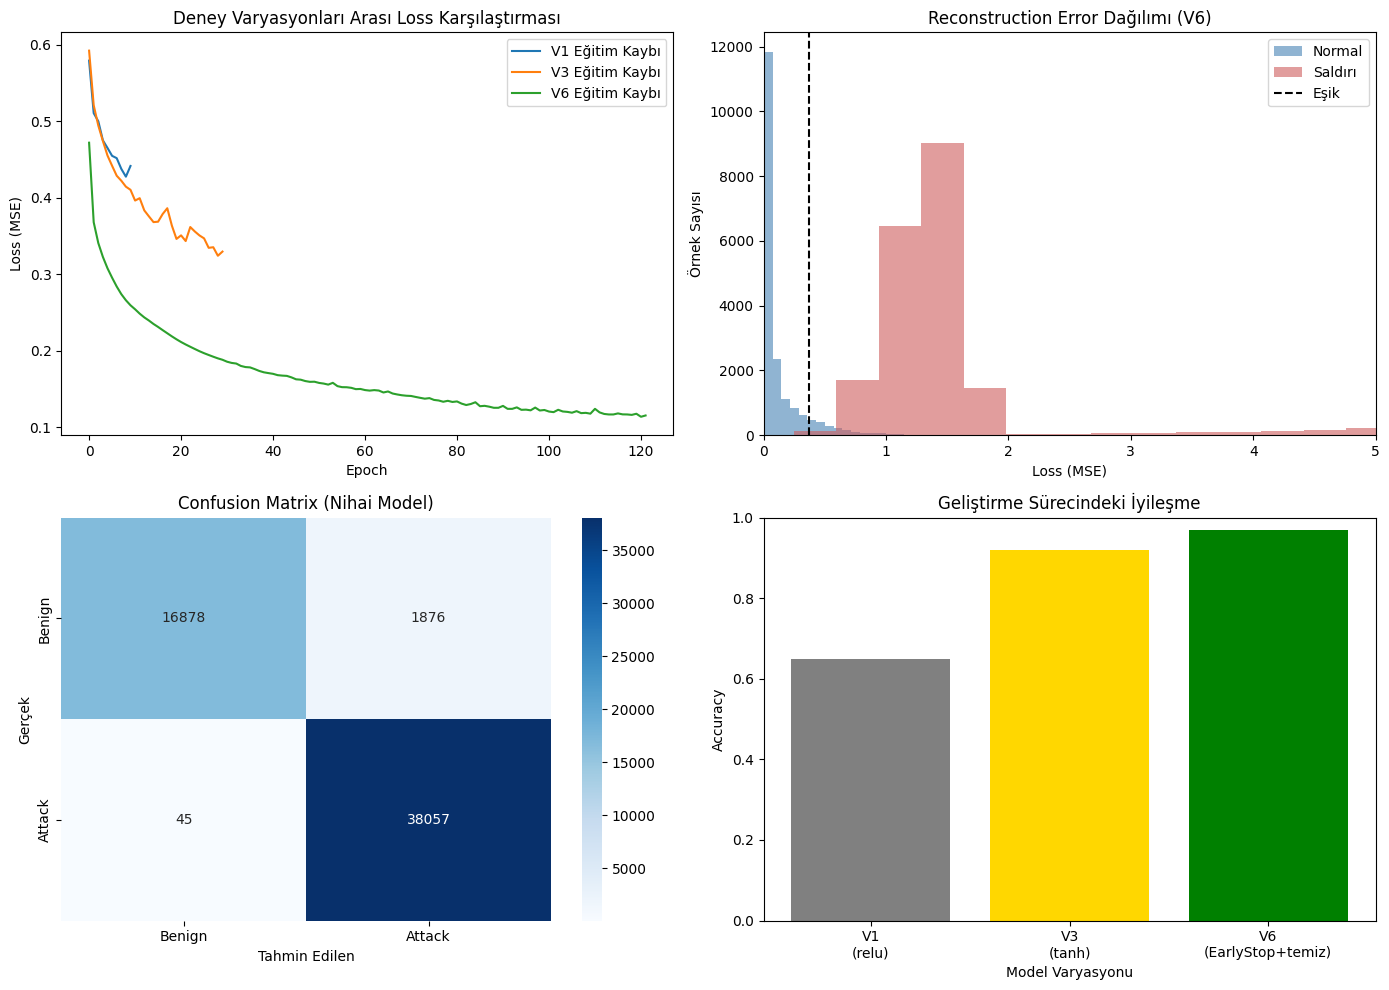

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0,0].plot(history.history['loss'], label='V1 Eğitim Kaybı')
axes[0,0].plot(history_v3.history['loss'], label='V3 Eğitim Kaybı')
axes[0,0].plot(history_v6.history['loss'], label='V6 Eğitim Kaybı')
axes[0,0].set_title('Deney Varyasyonları Arası Loss Karşılaştırması')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('Loss (MSE)')
axes[0,0].legend()

axes[0,1].hist(error_benign_test_v6, bins=50, alpha=0.6, label='Normal', color='steelblue')
axes[0,1].hist(error_attack_v6, bins=50, alpha=0.6, label='Saldırı', color='indianred')
axes[0,1].axvline(final_threshold, color='black', linestyle='--', label='Eşik')
axes[0,1].set_title('Reconstruction Error Dağılımı (V6)')
axes[0,1].set_xlabel('Loss (MSE)')
axes[0,1].set_ylabel('Örnek Sayısı')
axes[0,1].legend()
axes[0,1].set_xlim(0, 5)

sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign','Attack'], yticklabels=['Benign','Attack'], ax=axes[1,0])
axes[1,0].set_title('Confusion Matrix (Nihai Model)')
axes[1,0].set_xlabel('Tahmin Edilen')
axes[1,0].set_ylabel('Gerçek')

model_names = ['V1\n(relu)', 'V3\n(tanh)', 'V6\n(EarlyStop+temiz)']
accuracies = [0.65, 0.92, 0.97]
axes[1,1].bar(model_names, accuracies, color=['gray','gold','green'])
axes[1,1].set_title('Geliştirme Sürecindeki İyileşme')
axes[1,1].set_xlabel('Model Varyasyonu')
axes[1,1].set_ylabel('Accuracy')
axes[1,1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('sonuclar_gorsel.png', dpi=150)
plt.show()

## 38. Nihai Modelin Sınıflandırma Metriklerinin Görselleştirilmesi

Attack sınıfına ait precision, recall ve F1-skor değerleri, sayısal değerleriyle birlikte bir bar grafiğinde sunulmuştur. Bu görsel, Bölüm 36'da metin olarak raporlanan sonuçların (Precision: 0.95, Recall: 1.00, F1: 0.98) görsel bir özetini sağlamakta ve üç metriğin de yüksek ve birbirine yakın seviyelerde olduğunu, yani modelin dengeli bir performans sergilediğini net bir şekilde göstermektedir.

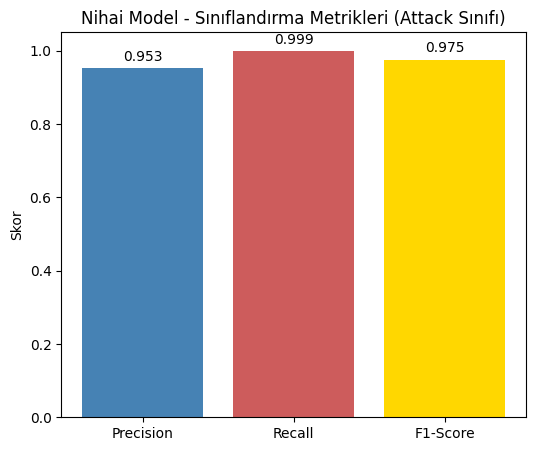

In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(all_true_labels_v6, final_pred, pos_label='Attack')
recall = recall_score(all_true_labels_v6, final_pred, pos_label='Attack')
f1 = f1_score(all_true_labels_v6, final_pred, pos_label='Attack')

metrics = ['Precision', 'Recall', 'F1-Score']
values = [precision, recall, f1]

plt.figure(figsize=(6,5))
bars = plt.bar(metrics, values, color=['steelblue','indianred','gold'])
plt.ylim(0,1.05)
plt.title('Nihai Model - Sınıflandırma Metrikleri (Attack Sınıfı)')
plt.ylabel('Skor')
for bar, v in zip(bars, values):
    plt.text(bar.get_x()+bar.get_width()/2, v+0.02, f'{v:.3f}', ha='center')
plt.show()

## 39. ROC Eğrisi: Eşikten Bağımsız Genel Performans Değerlendirmesi

Buraya kadarki değerlendirmeler belirli bir eşik değerine (90. persentil, optimal F1 vb.) bağlı olarak yapılmıştır. Bunu tamamlayıcı olarak, modelin tüm olası eşik değerlerindeki genel ayırt etme kapasitesini özetleyen ROC (Receiver Operating Characteristic) eğrisi ve AUC (Area Under Curve) değeri hesaplanmıştır.

Bu ek değerlendirmeyi eklemenin gerekçesi, Bölüm 36'da bahsedilen CBAM çalışmasının (Clausen vd., 2021) literatür taraması sırasında incelenmesiyle ortaya çıkmıştır; bu çalışma, model karşılaştırması için ROC eğrileri kullanmaktadır. Bu doğrultuda, bu projede de aynı değerlendirme aracının tamamlayıcı olarak sunulmasına karar verilmiştir. AUC değerinin 1'e yakınlığı, modelin normal ve saldırı davranışını, seçilen spesifik eşikten bağımsız olarak da güçlü şekilde ayırt edebildiğini göstermektedir.

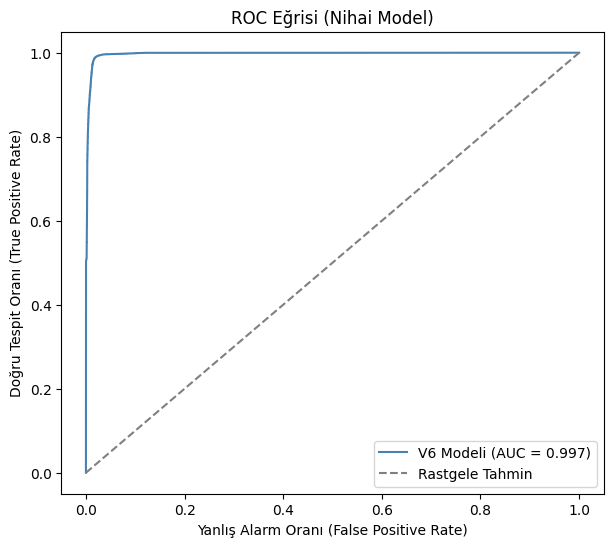

In [52]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, roc_thresholds = roc_curve(y_true_binary_v6, all_errors_v6)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, color='steelblue', label=f'V6 Modeli (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--', label='Rastgele Tahmin')
plt.xlabel('Yanlış Alarm Oranı (False Positive Rate)')
plt.ylabel('Doğru Tespit Oranı (True Positive Rate)')
plt.title('ROC Eğrisi (Nihai Model)')
plt.legend()
plt.show()

## 40. Sınırlılıklar ve Gelecek Çalışma Önerileri

Bu proje, EDR/XDR sistemlerinin davranışsal anomali tespiti yaklaşımını küçük ölçekte başarılı bir şekilde simüle etmiş olmakla birlikte, aşağıdaki sınırlılıkları ve geliştirmeye açık noktaları taşımaktadır:

**Kapsam Sınırlılıkları:**
- Bu çalışma, EDR/XDR'ların çok katmanlı yapısında yalnızca network-seviyesi davranışsal anomali tespiti (NDR'a karşılık gelen) katmanını simüle etmektedir. Gerçek EDR'ların ağırlık verdiği endpoint/process-seviyesi fileless/LOLBin tespiti (process zincirlerine bakan kısım) farklı bir veri altyapısı (process/sistem çağrısı telemetrisi, örn. DARPA OpTC) gerektirdiğinden kapsam dışında bırakılmıştır.
- Yalnızca brute force saldırı kategorisi (FTP/SSH) incelenmiştir; veri setinin diğer günlerinde yer alan DDoS, Bot, SQL Injection gibi saldırı türleri değerlendirilmemiştir.
- Kullanılan test kümesindeki saldırı/normal trafik oranı, gerçek operasyonel ortamlardaki tipik oranı yansıtmamaktadır; bu, CICIDS gibi laboratuvar ortamında üretilmiş veri setlerinin bilinen bir sınırlılığıdır.

**Metodolojik Geliştirme Alanları:**
- Pencere boyutu (window_size=10) sistematik bir optimizasyonla değil, makul bir başlangıç varsayımıyla seçilmiştir; farklı pencere boyutlarının (5, 15, 20 vb.) daha kapsamlı bir duyarlılık analizi ile karşılaştırılması faydalı olabilir. Window=20 denemesi başlangıçta bu amaçla (daha büyük bir pencerenin saldırı örüntüsünü daha güçlü yakalayıp yakalamadığını sınamak) başlatılmış; ancak süreç, veri kalitesinde beklenmedik bir outlier sorununun keşfedilmesiyle bir hata-ayıklama araştırmasına dönüşmüştür (bkz. Bölüm 15-27). Bu araştırma sonucunda hem kirli hem temizlenmiş window=20 verisi hazırlanmış olsa da, temizlenmiş window=20 verisiyle model yeniden eğitilip window=10 ile karşılaştırılması bu çalışmada tamamlanamamıştır; bu, doğrudan bir gelecek çalışma önerisi olarak not edilmektedir.
- Benign dizilerin train/test ayrımı zaman sırasına göre değil rastgele yapılmıştır; zaman-bazlı bir ayrım (örneğin ilk %70'lik zaman dilimini train, kalanını test yapmak) metodolojik olarak daha sağlam olabilir.
- Aynı saldırı olayına ait ardışık pencerelerin test kümesinde birlikte bulunması, örnekler arası tam istatistiksel bağımsızlık varsayımını zayıflatabilir; saldırı-bazlı (pencere-bazlı değil) bir train/test ayrımı bu noktayı güçlendirebilir.

**Gelecek Çalışma Önerileri:**
- Bu çalışma ile CBAM (Clausen vd., 2021) arasındaki metodolojik farklar (session yapısını zaman aralığına göre dinamik kurma, bidirectional LSTM, prediction-tabanlı — reconstruction değil — bir yaklaşım, kategorik vocabulary/embedding sistemi kullanımı, ROC-AUC ağırlıklı değerlendirme) bu raporun ilgili bölümlerinde (Bölüm 36, 39) kısmen ele alınmıştır. Ancak bu karşılaştırma şu ana kadar niteliksel düzeyde kalmıştır; gelecek bir çalışmada, CBAM'ın session-bazlı dinamik gruplama ve bidirectional/prediction-tabanlı mimarisinin bu projenin veri setine (CICIDS2018 brute force alt kümesi) doğrudan uygulanarak nicel bir performans karşılaştırmasının yapılması, iki yaklaşımın güçlü ve zayıf yönlerini daha kesin biçimde ortaya koyacaktır. Ayrıca bu çalışma yalnızca brute-force saldırı kategorisine (FTP/SSH) odaklanırken, CBAM CICIDS-17 veri setinde toplam yedi farklı saldırı türünü tespit edebilmekte, ayrıca LANL-15'teki gerçek-dünya red-team saldırısını ve UGR-16'daki uzun-vadeli benign trafiği de değerlendirerek daha geniş bir kapsamda test edilmiştir; bu çalışmadaki yaklaşımın CICIDS2018'in diğer saldırı türlerini içeren alt kümelerine genişletilerek benzer bir çeşitlilikte değerlendirilmesi de ayrı bir gelecek çalışma yönü olarak ele alınabilir.
- Precision-recall dengesini daha ince ayarlamak için F-beta skoru gibi alternatif eşik optimizasyon stratejileri sistematik olarak karşılaştırılabilir.